In [12]:
# ==========================================
# STEP 1 — LOAD MODEL DATA
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv(
    "hospital_ransomware_model_data.csv"
)
threat_data = pd.read_csv(
    "threat_database.csv"
)

print("Dataset shape:", data.shape)

print("\nFirst 5 rows:")
print(data.head())

print("\nSeverity distribution:")
print(
    data["disruption_severity"]
    .value_counts()
    .sort_index()
)

Dataset shape: (131, 9)

First 5 rows:
     CCN  threat_id  Tot_Benes  Tot_Dschrgs  Tot_Cvrd_Days  \
0  10045      127.0      159.0        197.0          669.0   
1  10092      127.0     3199.0       4704.0        27286.0   
2  10144      113.0     1340.0       1760.0         9002.0   
3  50039      139.0     5112.0       7674.0        35074.0   
4  50063        3.0     1584.0       2013.0        12049.0   

   Bene_Avg_Risk_Scre  avg_length_of_stay  hospitals_affected  \
0            1.866420            3.395939                   2   
1            2.164718            5.800595                   2   
2            2.122711            5.114773                   1   
3            1.980061            4.570498                   1   
4            3.084126            5.985594                   1   

   disruption_severity  
0                    1  
1                    1  
2                    0  
3                    1  
4                    1  

Severity distribution:
disruption_severity
0  

In [2]:
# ==========================================
# STEP 2 — DEFINE FEATURES, TARGET AND GROUPS
# ==========================================

feature_columns = [
    "Tot_Dschrgs",
    "Bene_Avg_Risk_Scre",
    "avg_length_of_stay"
]

X = data[feature_columns].copy()

y = data["disruption_severity"].copy()

# VERY IMPORTANT:
# hospitals affected by the same ransomware event
# must remain together during validation
groups = data["threat_id"].copy()

print("Features:")
print(feature_columns)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nUnique ransomware events:")
print(groups.nunique())

print("\nTarget distribution:")
print(y.value_counts().sort_index())

Features:
['Tot_Dschrgs', 'Bene_Avg_Risk_Scre', 'avg_length_of_stay']

X shape: (131, 3)
y shape: (131,)

Unique ransomware events:
64

Target distribution:
disruption_severity
0    55
1    46
2    30
Name: count, dtype: int64


In [3]:
# ==========================================
# STEP 3 — BASELINE MODEL
# ==========================================

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupKFold, cross_validate

baseline = DummyClassifier(
    strategy="most_frequent"
)

cv = GroupKFold(n_splits=5)

scoring = {
    "balanced_accuracy": "balanced_accuracy",
    "macro_f1": "f1_macro"
}

baseline_scores = cross_validate(
    baseline,
    X,
    y,
    groups=groups,
    cv=cv,
    scoring=scoring
)

print("BASELINE RESULTS")

print(
    "Mean Balanced Accuracy:",
    baseline_scores[
        "test_balanced_accuracy"
    ].mean()
)

print(
    "Mean Macro F1:",
    baseline_scores[
        "test_macro_f1"
    ].mean()
)

BASELINE RESULTS
Mean Balanced Accuracy: 0.3666666666666666
Mean Macro F1: 0.1547767591885239


In [4]:
# ==========================================
# STEP 4 — MULTINOMIAL LOGISTIC REGRESSION
# ==========================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        )
    )
])

logistic_scores = cross_validate(
    logistic_model,
    X,
    y,
    groups=groups,
    cv=cv,
    scoring=scoring
)

print("LOGISTIC REGRESSION RESULTS")

print(
    "Mean Balanced Accuracy:",
    logistic_scores[
        "test_balanced_accuracy"
    ].mean()
)

print(
    "Mean Macro F1:",
    logistic_scores[
        "test_macro_f1"
    ].mean()
)

LOGISTIC REGRESSION RESULTS
Mean Balanced Accuracy: 0.42028265107212476
Mean Macro F1: 0.3211553522729993


/opt/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


In [5]:
# ==========================================
# STEP 5 — DECISION TREE
# ==========================================

from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=8,
    class_weight="balanced",
    random_state=42
)

tree_scores = cross_validate(
    tree_model,
    X,
    y,
    groups=groups,
    cv=cv,
    scoring=scoring
)

print("DECISION TREE RESULTS")

print(
    "Mean Balanced Accuracy:",
    tree_scores[
        "test_balanced_accuracy"
    ].mean()
)

print(
    "Mean Macro F1:",
    tree_scores[
        "test_macro_f1"
    ].mean()
)

DECISION TREE RESULTS
Mean Balanced Accuracy: 0.3754358117516013
Mean Macro F1: 0.29751922272003406


/opt/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


In [6]:
# ==========================================
# STEP 6 — COMPARE MODELS
# ==========================================

results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Logistic Regression",
        "Decision Tree"
    ],

    "Balanced Accuracy": [
        baseline_scores[
            "test_balanced_accuracy"
        ].mean(),

        logistic_scores[
            "test_balanced_accuracy"
        ].mean(),

        tree_scores[
            "test_balanced_accuracy"
        ].mean()
    ],

    "Macro F1": [
        baseline_scores[
            "test_macro_f1"
        ].mean(),

        logistic_scores[
            "test_macro_f1"
        ].mean(),

        tree_scores[
            "test_macro_f1"
        ].mean()
    ]
})

print(results.round(3))

                 Model  Balanced Accuracy  Macro F1
0             Baseline              0.367     0.155
1  Logistic Regression              0.420     0.321
2        Decision Tree              0.375     0.298


In [7]:
# ==========================================
# STEP 7 — GROUPED OUT-OF-FOLD PREDICTIONS
# ==========================================

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

y_pred_logistic = cross_val_predict(
    logistic_model,
    X,
    y,
    groups=groups,
    cv=cv,
    method="predict"
)

print("CONFUSION MATRIX")
print(confusion_matrix(y, y_pred_logistic))

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y,
        y_pred_logistic,
        target_names=[
            "Low",
            "Moderate",
            "High"
        ],
        digits=3
    )
)

CONFUSION MATRIX
[[26 12 17]
 [16 13 17]
 [ 8 12 10]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Low      0.520     0.473     0.495        55
    Moderate      0.351     0.283     0.313        46
        High      0.227     0.333     0.270        30

    accuracy                          0.374       131
   macro avg      0.366     0.363     0.360       131
weighted avg      0.394     0.374     0.380       131



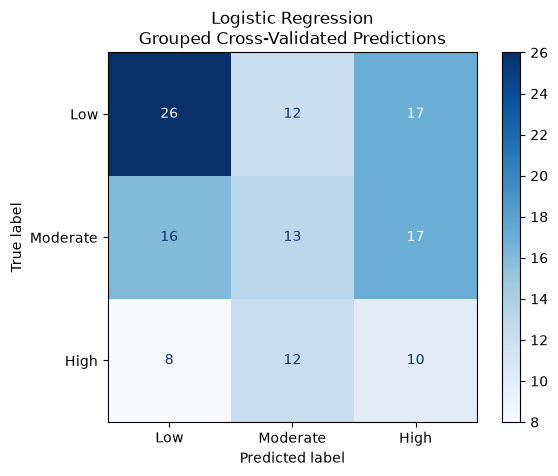

In [8]:
# ==========================================
# STEP 8 — VISUALIZE CONFUSION MATRIX
# ==========================================

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y,
    y_pred_logistic,
    display_labels=[
        "Low",
        "Moderate",
        "High"
    ],
    cmap="Blues"
)

plt.title(
    "Logistic Regression\n"
    "Grouped Cross-Validated Predictions"
)

plt.show()

In [9]:
# ==========================================
# STEP 9 — MODEL WITH ATTACK SCOPE
# ==========================================

feature_columns_scope = [
    "Tot_Dschrgs",
    "Bene_Avg_Risk_Scre",
    "avg_length_of_stay",
    "hospitals_affected"
]

X_scope = data[
    feature_columns_scope
].copy()

scope_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        )
    )
])

scope_scores = cross_validate(
    scope_model,
    X_scope,
    y,
    groups=groups,
    cv=cv,
    scoring=scoring
)

print("HOSPITAL-ONLY MODEL")
print(
    "Balanced Accuracy:",
    logistic_scores[
        "test_balanced_accuracy"
    ].mean()
)
print(
    "Macro F1:",
    logistic_scores[
        "test_macro_f1"
    ].mean()
)

print("\nHOSPITAL + ATTACK SCOPE MODEL")
print(
    "Balanced Accuracy:",
    scope_scores[
        "test_balanced_accuracy"
    ].mean()
)
print(
    "Macro F1:",
    scope_scores[
        "test_macro_f1"
    ].mean()
)

HOSPITAL-ONLY MODEL
Balanced Accuracy: 0.42028265107212476
Macro F1: 0.3211553522729993

HOSPITAL + ATTACK SCOPE MODEL
Balanced Accuracy: 0.27391743247006406
Macro F1: 0.24533800089654276


/opt/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


In [14]:
# ==========================================
# STEP 15 — INSPECT AVAILABLE THREAT VARIABLES
# ==========================================

print("All columns in original THREAT dataset:")
print()

for i, column in enumerate(threat_data.columns, start=1):
    print(i, column)

All columns in original THREAT dataset:

1 medicare_id
2 attacked
3 attack_date
4 er_diversion
5 cancel_delay
6 threat_id
7 nearest_neighbor
8 origin_threat_id1
9 origin_threat_id2
10 origin_threat_id3
11 origin_threat_id4
12 origin_threat_id5
13 origin_threat_id6
14 origin_threat_id7
